# Notebook 2 — Can Hardness Data Help Predict Yield Strength?

**This is the main experiment of the paper.**

### The idea in one paragraph

Measuring **yield strength** needs a compression or tension test: a carefully machined sample, a big testing machine, and time. Measuring **Vickers hardness** needs only a small polished piece and a few minutes. Hardness and strength are physically related (Tabor's rule: $\sigma_y \approx H_V \times 9.807 / 3$). In Notebook 1 we found **189 alloys that have hardness but no yield strength**. This notebook asks:

> *Does adding cheap hardness data make machine-learning predictions of yield strength better? And in which situations?*

### Two realistic situations (scenarios)

| Scenario | What we know about the **new** alloys we want to predict | Real-life meaning |
|---|---|---|
| **A: no hardness for new alloys** | Only their composition | Pure computer screening of alloys nobody has made yet |
| **B: hardness measured for new alloys** | Composition **and** a quick hardness test | You made small samples, measured hardness (cheap), and want to know the yield strength before doing expensive mechanical tests |

### Five methods we compare

| Method | Short name | Uses hardness how? |
|---|---|---|
| M0 | Baseline | Not at all (same as Notebook 1) |
| M1 | Tabor rule | Strength = HV × 9.807 / 3, no machine learning |
| M2 | Hardness as input | Measured hardness is given to the model as an extra feature (scenario B) |
| M3 | Augment (A) | Hardness alloys are turned into extra training rows with a Tabor "pseudo-strength"; hardness of the test alloys is **hidden** |
| M4 | Augment (B) | Same as M3, but hardness of the test alloys **is** available (it was measured) |

**Before you start:** run Notebook 1 first (it downloads the data into the `data/` folder). This notebook will download the data again if it cannot find it.

## Step 1 — Import the libraries

In [1]:
import os
import re
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymatgen.core import Element
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

# Colours used in all figures of the project
COLOR_BLUE   = "#2a78d6"
COLOR_ORANGE = "#eb6834"
COLOR_GREEN  = "#1baf7a"

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("Libraries imported.")

Libraries imported.


## Step 2 — Helper functions from Notebook 1

These are the same functions we wrote and explained in Notebook 1. We copy them here so this notebook can run on its own:

* `parse_formula`: text formula → atomic fractions
* `make_composition_id` / `make_system_id`: labels used for grouped validation
* `physics_descriptors`: size mismatch δ, mixing entropy, VEC, electronegativity, melting point, ...

In [2]:
def parse_formula(formula):
    '''"Al0.25 Co1 Fe1 Ni1" -> {"Al": 0.077, "Co": 0.308, ...} (atomic fractions).'''
    pairs = re.findall(r"([A-Z][a-z]?)([0-9.]+)", formula)
    amounts = {}
    for element, amount in pairs:
        amounts[element] = amounts.get(element, 0) + float(amount)
    total = sum(amounts.values())
    return {element: amount / total for element, amount in amounts.items()}

def make_composition_id(comp):
    '''Exact composition label, e.g. "Co0.333-Cr0.333-Fe0.333".'''
    return "-".join(f"{el}{round(frac, 3)}" for el, frac in sorted(comp.items()))

def make_system_id(comp):
    '''Element-system (alloy family) label, e.g. "Co-Cr-Fe".'''
    return "-".join(sorted(comp.keys()))

def valence_electrons(symbol):
    '''VEC of one element: group number for transition metals, group - 10 for Al, Si, Sn, ...'''
    group = Element(symbol).group
    return group if group <= 12 else group - 10

def element_radius(symbol):
    '''Metallic radius if available, otherwise atomic radius (in Å).'''
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # hide "no data" warnings for C, Si, Sn
        radius = Element(symbol).metallic_radius
    if radius is None or radius == 0:
        radius = Element(symbol).atomic_radius
    return float(radius)

def build_element_table(elements):
    '''Look up the properties we need for every element, once.'''
    return pd.DataFrame({
        "radius":     {el: element_radius(el)               for el in elements},
        "electroneg": {el: float(Element(el).X)             for el in elements},
        "melting_K":  {el: float(Element(el).melting_point) for el in elements},
        "vec":        {el: valence_electrons(el)            for el in elements},
    })

def physics_descriptors(comp, element_table):
    '''Physics descriptors of one alloy (see Notebook 1, Step 6 for the formulas).'''
    elements = list(comp.keys())
    c   = np.array([comp[el] for el in elements])
    r   = element_table.loc[elements, "radius"].values
    chi = element_table.loc[elements, "electroneg"].values
    tm  = element_table.loc[elements, "melting_K"].values
    vec = element_table.loc[elements, "vec"].values
    r_mean, chi_mean = np.sum(c * r), np.sum(c * chi)
    return {
        "delta_size_mismatch": 100 * np.sqrt(np.sum(c * (1 - r / r_mean) ** 2)),
        "S_mix":               -8.314 * np.sum(c * np.log(c)),
        "VEC":                 np.sum(c * vec),
        "chi_mean":            chi_mean,
        "delta_chi":           np.sqrt(np.sum(c * (chi - chi_mean) ** 2)),
        "Tm_mean":             np.sum(c * tm),
        "r_mean":              r_mean,
        "n_elements":          len(elements),
    }

print("Helper functions ready.")

Helper functions ready.


## Step 3 — Load the data and make two tables

We make two tables from the same dataset:

1. **Strength table:** room-temperature yield strength, cleaned exactly as in Notebook 1.
2. **Hardness table:** every row with a Vickers hardness value.

**A subtle cleaning detail:** in the original file, when one paper tested the same alloy at several temperatures, the *same* hardness value is copied into every one of those rows. If we kept them all, one hardness measurement would count 5–10 times. So we remove repeated rows that have the same alloy, processing, hardness value, *and* paper.

In [3]:
DATA_FILE = "data/MPEA_dataset.csv"
if not os.path.exists(DATA_FILE):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/CitrineInformatics/MPEA_dataset/master/MPEA_dataset.csv", DATA_FILE)

raw = pd.read_csv(DATA_FILE)
raw = raw.rename(columns={
    "IDENTIFIER: Reference ID":                 "ref_id",
    "FORMULA":                                  "formula",
    "PROPERTY: Processing method":              "processing",
    "PROPERTY: HV":                             "hardness_HV",
    "PROPERTY: Type of test":                   "test_type",
    "PROPERTY: Test temperature ($^\\circ$C)":  "test_temp_C",
    "PROPERTY: YS (MPa)":                       "yield_strength_MPa",
})
raw["processing"] = raw["processing"].fillna("unknown")
raw["test_type"]  = raw["test_type"].fillna("unknown")

# Composition and the two group labels for every row
raw["composition"]    = raw["formula"].apply(parse_formula)
raw["composition_id"] = raw["composition"].apply(make_composition_id)
raw["system_id"]      = raw["composition"].apply(make_system_id)

# ---- Table 1: yield strength at room temperature (same rules as Notebook 1) ----
strength = raw[raw["yield_strength_MPa"].notna() & raw["test_temp_C"].between(20, 30)]
strength = strength[(strength["yield_strength_MPa"] > 0) & (strength["yield_strength_MPa"] < 5000)]
strength = strength.reset_index(drop=True)

# ---- Table 2: hardness (remove the copied duplicates explained above) ----
hardness = raw[raw["hardness_HV"].notna()]
print("Hardness rows before removing copies:", len(hardness))
hardness = hardness.drop_duplicates(subset=["composition_id", "processing", "hardness_HV", "ref_id"])
hardness = hardness.reset_index(drop=True)
print("Hardness rows after removing copies: ", len(hardness))

print("\nStrength table:", len(strength), "rows,", strength["composition_id"].nunique(), "distinct alloys")
print("Hardness table:", len(hardness), "rows,", hardness["composition_id"].nunique(), "distinct alloys")

Hardness rows before removing copies: 530
Hardness rows after removing copies:  516

Strength table: 722 rows, 394 distinct alloys
Hardness table: 516 rows, 377 distinct alloys


### Step 3b — Give each strength row its measured hardness (if any)

For **scenario B** we need to know, for each strength measurement, whether the *same alloy* also has a hardness value. If an alloy has several hardness values (different papers), we use their average.

In [4]:
# Average hardness of every alloy (one number per composition_id)
mean_hv_per_alloy = hardness.groupby("composition_id")["hardness_HV"].mean()

# Look up each strength row's alloy in that list; alloys without hardness get NaN (missing)
strength["HV_measured"] = strength["composition_id"].map(mean_hv_per_alloy)

has_hardness = strength["HV_measured"].notna().values   # True/False for every row
print(f"Strength rows whose alloy also has hardness: {has_hardness.sum()} of {len(strength)}")

Strength rows whose alloy also has hardness: 397 of 722


## Step 4 — Build the features for both tables

Both tables must have **exactly the same feature columns**, otherwise we cannot put them together for training. The easiest way: stack the two tables on top of each other, build all features at once, then split them apart again.

The **test type** column gets a new value, `"hardness"`, for the hardness rows. This lets the model learn that a "pseudo-strength" from hardness is a slightly different kind of measurement than a real compression or tension test.

In [5]:
# Mark where each row came from
strength_part = strength.assign(source="strength")
hardness_part = hardness.assign(source="hardness", test_type="hardness")
both_tables   = pd.concat([strength_part, hardness_part], ignore_index=True)

# (a) Element fractions
fractions = pd.DataFrame(list(both_tables["composition"])).fillna(0)
fractions.columns = ["frac_" + el for el in fractions.columns]

# (b) Physics descriptors
all_elements  = sorted({el for comp in both_tables["composition"] for el in comp})
element_table = build_element_table(all_elements)
physics = pd.DataFrame([physics_descriptors(comp, element_table) for comp in both_tables["composition"]])

# (c) Test type and processing as 0/1 columns
categories = pd.get_dummies(both_tables[["test_type", "processing"]], prefix=["test", "proc"], dtype=int)

features_all = pd.concat([fractions, physics, categories], axis=1)

# Split back into the two tables
is_strength_row = (both_tables["source"] == "strength").values
X_strength = features_all[is_strength_row].reset_index(drop=True)
X_hardness = features_all[~is_strength_row].reset_index(drop=True)

# Targets
y_strength = strength["yield_strength_MPa"].values
# Tabor "pseudo-strength" for every hardness row: HV (kgf/mm²) × 9.807 → MPa, divided by 3
y_hardness_pseudo = hardness["hardness_HV"].values * 9.807 / 3

print("X_strength:", X_strength.shape, "  X_hardness:", X_hardness.shape)

X_strength: (722, 45)   X_hardness: (516, 45)


## Step 5 — Repeated grouped cross-validation

In Notebook 1 we ran each test once. But the result depends a little on *which* alloys happen to land in which fold. To get trustworthy numbers we **repeat the whole 5-fold test with 5 different random seeds** and report the **average ± standard deviation**. A difference between two methods is only convincing if it is clearly larger than this standard deviation.

We write our own small function that randomly assigns each **group** (alloy or alloy family) to one of the 5 folds. All rows of a group always land in the same fold.

In [6]:
def assign_group_folds(groups, n_folds, seed):
    '''
    Randomly give every group a fold number 0..n_folds-1.
    Returns a dictionary {group label: fold number}.
    '''
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(seed)          # random number generator with a fixed seed
    rng.shuffle(unique_groups)                 # shuffle the order of the groups
    # Deal the shuffled groups out like playing cards: 0, 1, 2, 3, 4, 0, 1, ...
    return {group: i % n_folds for i, group in enumerate(unique_groups)}

# Quick test with 6 made-up groups and 3 folds
print(assign_group_folds(np.array(["a", "a", "b", "c", "d", "e", "f"]), n_folds=3, seed=0))

{np.str_('d'): 0, np.str_('c'): 1, np.str_('f'): 2, np.str_('e'): 0, np.str_('a'): 1, np.str_('b'): 2}


## Step 6 — The model and the methods

We use **XGBoost**, the best model in Notebook 1, with the same settings for every method. Only the *data* we give it changes, so any difference in accuracy comes from how hardness is used, not from the model.

### Pseudo-label weight

Pseudo-strengths from Tabor's rule are less reliable than real strength tests. We tell the model to trust them **half as much** (`sample_weight = 0.5`). We chose 0.5 as a sensible middle value *before* looking at the results. In Step 9 we check that the conclusions do not depend on this choice.

In [7]:
N_FOLDS       = 5
SEEDS         = [0, 1, 2, 3, 4]      # 5 repetitions
PSEUDO_WEIGHT = 0.5                  # how much to trust hardness-based pseudo-strengths

def make_model(seed):
    '''Same XGBoost settings for every method.'''
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8,
                        random_state=seed, n_jobs=-1)

The function below runs **one** method with **one** seed and **one** grouping, and returns a prediction for every strength row (each row predicted while it was in the test fold).

Read the comments for each method carefully. The most important detail is in **M3**: hardness rows that belong to a test group are **removed** from training, because in scenario A we pretend we have no hardness for the new alloys.

In [8]:
def run_method(method, group_column, seed, pseudo_weight=PSEUDO_WEIGHT):
    '''Return out-of-fold predictions of yield strength for every row of the strength table.'''

    # Fold numbers for strength rows and hardness rows (same group -> same fold)
    fold_of_group = assign_group_folds(strength[group_column].values, N_FOLDS, seed)
    strength_fold = strength[group_column].map(fold_of_group).values
    # Hardness rows of alloys/families that have NO strength data are never test rows: fold -1
    hardness_fold = hardness[group_column].map(fold_of_group).fillna(-1).values

    predictions = np.zeros(len(strength))

    for fold in range(N_FOLDS):
        train = strength_fold != fold          # True for training rows
        test  = strength_fold == fold          # True for test rows

        if method == "M0 Baseline":
            # Only real strength data, no hardness at all
            model = make_model(seed).fit(X_strength[train], y_strength[train])
            predictions[test] = model.predict(X_strength[test])

        elif method == "M1 Tabor rule":
            # No machine learning: strength = HV x 9.807 / 3 (NaN if the alloy has no hardness)
            predictions[test] = strength["HV_measured"].values[test] * 9.807 / 3

        elif method == "M2 Hardness as input":
            # Measured hardness is an extra feature. Alloys without hardness get NaN;
            # XGBoost can handle missing values by itself.
            X_plus = X_strength.copy()
            X_plus["HV_measured"] = strength["HV_measured"].values
            model = make_model(seed).fit(X_plus[train], y_strength[train])
            predictions[test] = model.predict(X_plus[test])

        elif method in ("M3 Augment (A)", "M4 Augment (B)"):
            if method == "M3 Augment (A)":
                # Scenario A: hide the hardness of the test alloys/families
                use_hardness = hardness_fold != fold
            else:
                # Scenario B: hardness of all alloys is known, including the test alloys
                use_hardness = np.ones(len(hardness), dtype=bool)

            # Stack real strength rows + hardness pseudo-strength rows
            X_train = pd.concat([X_strength[train], X_hardness[use_hardness]])
            y_train = np.concatenate([y_strength[train], y_hardness_pseudo[use_hardness]])
            weights = np.concatenate([np.ones(train.sum()),                        # real rows: weight 1
                                      np.full(use_hardness.sum(), pseudo_weight)]) # pseudo rows: lower weight

            model = make_model(seed).fit(X_train, y_train, sample_weight=weights)
            # We always TEST on real strength measurements only
            predictions[test] = model.predict(X_strength[test])

    return predictions

## Step 7 — Run the full experiment

5 methods × 2 groupings × 5 seeds. Each prediction is scored twice:

* on **all** strength rows, and
* on the **subset** of rows whose alloy has a measured hardness. This is the fair comparison with M1 and M2, which only use hardness where it exists.

This takes about 1–3 minutes.

In [9]:
METHODS   = ["M0 Baseline", "M1 Tabor rule", "M2 Hardness as input", "M3 Augment (A)", "M4 Augment (B)"]
GROUPINGS = {"New alloy (composition)": "composition_id",
             "New alloy family (system)": "system_id"}

rows = []            # one result row per (grouping, method, seed)
saved_predictions = {}

for grouping_name, group_column in GROUPINGS.items():
    for method in METHODS:
        for seed in SEEDS:
            pred = run_method(method, group_column, seed)
            saved_predictions[(grouping_name, method, seed)] = pred

            row = {"Grouping": grouping_name, "Method": method, "Seed": seed}
            if method != "M1 Tabor rule":                       # Tabor has no prediction without hardness
                row["R2 (all)"]  = r2_score(y_strength, pred)
                row["MAE (all)"] = mean_absolute_error(y_strength, pred)
            row["R2 (subset)"]  = r2_score(y_strength[has_hardness], pred[has_hardness])
            row["MAE (subset)"] = mean_absolute_error(y_strength[has_hardness], pred[has_hardness])
            rows.append(row)
        print(f"done: {grouping_name:28s} {method}")

per_seed = pd.DataFrame(rows)
per_seed.to_csv("results/table2_per_seed_results.csv", index=False)

done: New alloy (composition)      M0 Baseline
done: New alloy (composition)      M1 Tabor rule


done: New alloy (composition)      M2 Hardness as input


done: New alloy (composition)      M3 Augment (A)


done: New alloy (composition)      M4 Augment (B)


done: New alloy family (system)    M0 Baseline
done: New alloy family (system)    M1 Tabor rule


done: New alloy family (system)    M2 Hardness as input


done: New alloy family (system)    M3 Augment (A)


done: New alloy family (system)    M4 Augment (B)


## Step 8 — Results table (mean ± standard deviation over 5 seeds)

In [10]:
metric_cols = ["R2 (all)", "MAE (all)", "R2 (subset)", "MAE (subset)"]
mean_table = per_seed.groupby(["Grouping", "Method"])[metric_cols].mean()
std_table  = per_seed.groupby(["Grouping", "Method"])[metric_cols].std()

def mean_pm_std(mean, std, decimals):
    '''Format numbers as "0.650 ± 0.010"; show "-" where the method gives no value.'''
    if pd.isna(mean):
        return "-"
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

pretty = pd.DataFrame(index=mean_table.index)
for col in metric_cols:
    decimals = 3 if col.startswith("R2") else 0
    pretty[col] = [mean_pm_std(m, s, decimals) for m, s in zip(mean_table[col], std_table[col])]

pretty.to_csv("results/table2_summary.csv")
pretty

R2 (all) MAE (all)  \
Grouping                  Method                                          
New alloy (composition)   M0 Baseline           0.670 ± 0.020   246 ± 7   
                          M1 Tabor rule                     -         -   
                          M2 Hardness as input  0.698 ± 0.009   240 ± 3   
                          M3 Augment (A)        0.673 ± 0.019   247 ± 8   
                          M4 Augment (B)        0.721 ± 0.010   230 ± 2   
New alloy family (system) M0 Baseline           0.545 ± 0.019   291 ± 8   
                          M1 Tabor rule                     -         -   
                          M2 Hardness as input  0.607 ± 0.010   273 ± 5   
                          M3 Augment (A)        0.550 ± 0.024  292 ± 11   
                          M4 Augment (B)        0.645 ± 0.015   267 ± 7   

                                                  R2 (subset) MAE (subset)  
Grouping                  Method                                            
New alloy (composition)   M0 Baseline           0.617 ± 0.027     273 ± 10  
                          M1 Tabor rule         0.430 ± 0.000      353 ± 0  
                          M2 Hardness as input  0.664 ± 0.016      259 ± 4  
                          M3 Augment (A)        0.615 ± 0.026     276 ± 12  
                          M4 Augment (B)        0.696 ± 0.008      247 ± 3  
New alloy family (system) M0 Baseline           0.506 ± 0.022     309 ± 12  
                          M1 Tabor rule         0.430 ± 0.000      353 ± 0  
                          M2 Hardness as input  0.586 ± 0.016      287 ± 6  
                          M3 Augment (A)        0.494 ± 0.031     315 ± 13  
                          M4 Augment (B)        0.639 ± 0.016      275 ± 8

### Step 8b — Picture of the results

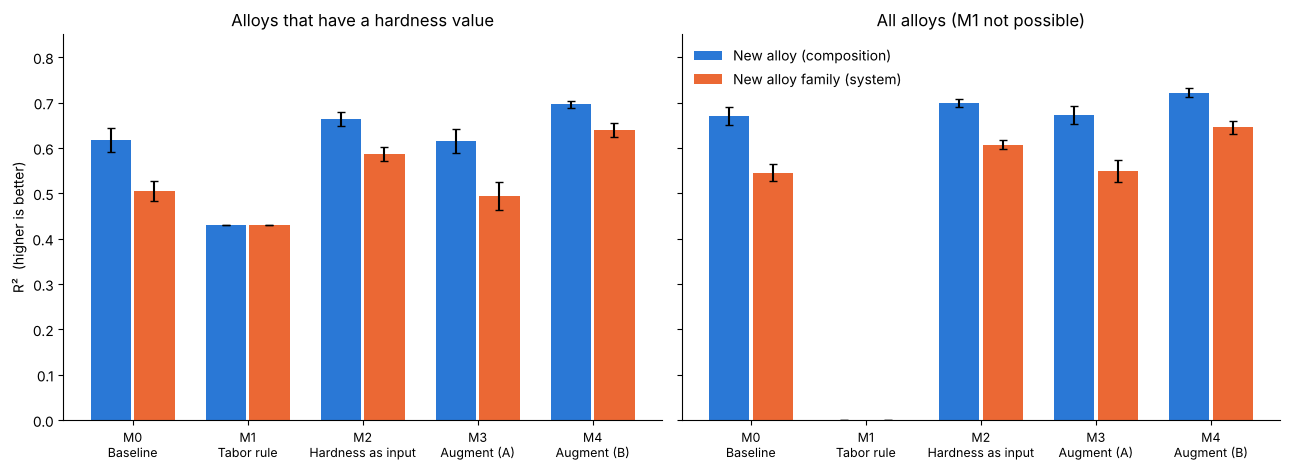

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
bar_width = 0.38
colors = {"New alloy (composition)": COLOR_BLUE, "New alloy family (system)": COLOR_ORANGE}

for ax, metric in zip(axes, ["R2 (subset)", "R2 (all)"]):
    x = np.arange(len(METHODS))
    for i, grouping_name in enumerate(GROUPINGS):
        means = [mean_table.loc[(grouping_name, m), metric] for m in METHODS]
        stds  = [std_table.loc[(grouping_name, m), metric] for m in METHODS]
        ax.bar(x + (i - 0.5) * bar_width, np.nan_to_num(means), bar_width * 0.92,
               yerr=np.nan_to_num(stds), capsize=3, color=colors[grouping_name], label=grouping_name)
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(" ", "\n", 1) for m in METHODS], fontsize=9)
    ax.set_ylim(0, 0.85)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_title("Alloys that have a hardness value")
axes[1].set_title("All alloys (M1 not possible)")
axes[0].set_ylabel("R²  (higher is better)")
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("figures/fig5_hardness_methods.png", dpi=300)
plt.show()

### Step 8c — Is the improvement consistent?

An average can hide surprises. Here we check, **seed by seed**, how much each hardness method improves R² over the baseline (M0) for new alloy families. If the improvement is positive for *every* seed, we can be much more confident it's real.

In [12]:
grouping_name = "New alloy family (system)"
base = per_seed[(per_seed.Grouping == grouping_name) & (per_seed.Method == "M0 Baseline")].set_index("Seed")["R2 (all)"]

improvement = {}
for method in ["M2 Hardness as input", "M3 Augment (A)", "M4 Augment (B)"]:
    this = per_seed[(per_seed.Grouping == grouping_name) & (per_seed.Method == method)].set_index("Seed")["R2 (all)"]
    improvement[method] = this - base

improvement = pd.DataFrame(improvement)
improvement.index.name = "Seed"
print("Change in R² compared with M0, new alloy family, every seed:")
display(improvement.round(3))
print("Seeds where the method was better than baseline:")
print((improvement > 0).sum().to_string())

Change in R² compared with M0, new alloy family, every seed:


,M2 Hardness as input,M3 Augment (A),M4 Augment (B)
Seed,,,
0,0.092,-0.002,0.103
1,0.063,0.002,0.111
2,0.033,-0.023,0.090
3,0.060,0.030,0.098
4,0.063,0.018,0.101


Seeds where the method was better than baseline:
M2 Hardness as input    5
M3 Augment (A)          3
M4 Augment (B)          5


### Step 8d — Parity plot: baseline vs. best method

Predictions for **new alloy families** (seed 0). Compare the spread of the points around the diagonal: with hardness (orange), the cloud is noticeably tighter.

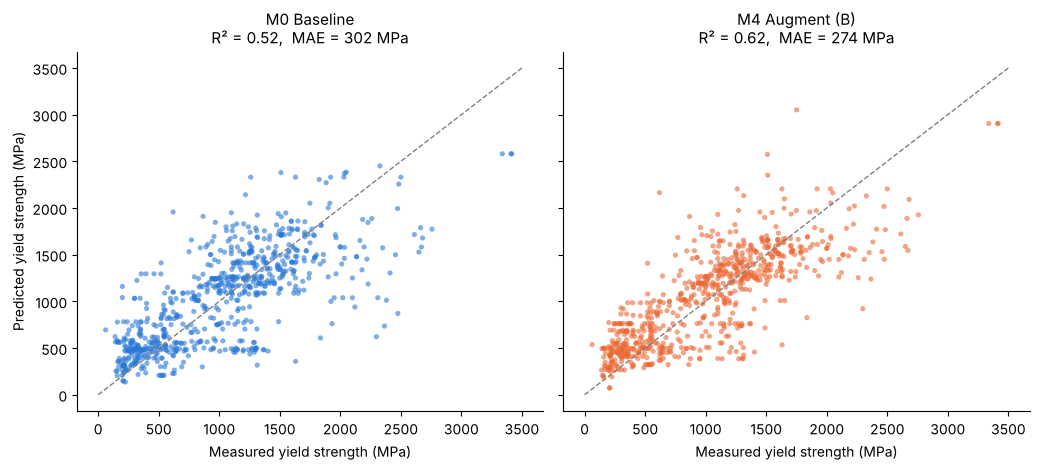

In [13]:
grouping_name = "New alloy family (system)"
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharex=True, sharey=True)

for ax, method, color in zip(axes, ["M0 Baseline", "M4 Augment (B)"], [COLOR_BLUE, COLOR_ORANGE]):
    pred = saved_predictions[(grouping_name, method, 0)]
    ax.scatter(y_strength, pred, s=14, alpha=0.6, color=color, edgecolor="none")
    ax.plot([0, 3500], [0, 3500], color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{method}\nR² = {r2_score(y_strength, pred):.2f},  "
                 f"MAE = {mean_absolute_error(y_strength, pred):.0f} MPa", fontsize=11)
    ax.set_xlabel("Measured yield strength (MPa)")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Predicted yield strength (MPa)")
plt.tight_layout()
plt.savefig("figures/fig6_parity_baseline_vs_augment.png", dpi=300)
plt.show()

## Step 9 — Robustness check: does the pseudo-label weight matter?

We chose `PSEUDO_WEIGHT = 0.5` in advance. A reviewer will ask: *"Would a different value change your conclusion?"* We re-run M3 and M4 with weights from 0.25 to 1.0 (3 seeds each, to save time).

In [14]:
weights_to_try = [0.25, 0.5, 0.75, 1.0]
sensitivity = []

for weight in weights_to_try:
    for method in ["M3 Augment (A)", "M4 Augment (B)"]:
        scores = [r2_score(y_strength, run_method(method, "system_id", seed, pseudo_weight=weight))
                  for seed in SEEDS[:3]]
        sensitivity.append({"Pseudo weight": weight, "Method": method,
                            "R2 mean": np.mean(scores), "R2 std": np.std(scores)})

sensitivity = pd.DataFrame(sensitivity)
baseline_r2 = mean_table.loc[("New alloy family (system)", "M0 Baseline"), "R2 (all)"]
print(f"Baseline (M0) R² for new alloy families: {baseline_r2:.3f}\n")
sensitivity.pivot(index="Pseudo weight", columns="Method", values="R2 mean").round(3)

Baseline (M0) R² for new alloy families: 0.545



Method,M3 Augment (A),M4 Augment (B)
Pseudo weight,,
0.25,0.539,0.639
0.50,0.534,0.642
0.75,0.551,0.644
1.00,0.542,0.646


If every weight gives a similar result, the conclusion is **robust**: it does not depend on a lucky choice of this setting.

## Step 10 — What do the results mean?

Look at your table from Step 8 and the figures. With the data we used when writing this notebook, the pattern was:

1. **Tabor's rule alone (M1) is the worst method.** A single factor of 3 is too simple for HEAs, and hardness and strength were often measured on differently processed samples.
2. **Scenario A (M3): hardness of *other* alloys gives no reliable improvement.** When the new alloys have no hardness, adding the extra hardness alloys changes R² by less than its seed-to-seed scatter, and it was better than the baseline in only some seeds (Step 8c). This negative result is worth reporting: it shows that hardness data is only useful when it covers the alloys you want to predict.
3. **Scenario B (M2, M4): hardness of the *new* alloys helps a lot**, especially for **new alloy families**, the hardest and most useful case for alloy discovery.
4. **Using hardness as extra training data (M4) works better than using it as an input feature (M2).** M2 can only use hardness for alloys that also have strength; M4 also learns from the 189 hardness-only alloys.

### The practical message of the paper

> *"Measure hardness first, then predict strength."* Cheap Vickers hardness tests on newly made alloys, combined with ML trained on both strength and hardness data, give clearly better yield-strength predictions than composition-based ML or Tabor's rule alone, while honest grouped validation shows that hardness data from *other* alloys gives no reliable improvement.

> **📝 For your paper**
> * **Methods:** describe the five methods, the two scenarios, the hardness deduplication (Step 3), the pseudo-label weight, and the 5 × 5-fold repeated grouped cross-validation.
> * **Results:** Table 2 (`results/table2_summary.csv`), Figure 5 (methods comparison), Figure 6 (parity plots), and the seed-by-seed consistency (Step 8c).
> * **Robustness:** the pseudo-weight sensitivity table (Step 9).
> * **Limitations (be honest, reviewers respect it):** hardness and strength sometimes come from different processing states; Tabor's factor 3 is an approximation; the dataset contains mostly cast and annealed alloys; scenario B assumes hardness can be measured for every new alloy.

## Step 11 — Save everything

In [15]:
# Out-of-fold predictions (seed 0) for every method, handy for later figures
out = strength[["formula", "composition_id", "system_id", "test_type", "processing",
                "yield_strength_MPa", "HV_measured"]].copy()
for grouping_name in GROUPINGS:
    for method in METHODS:
        short = f"{method.split()[0]}_{'comp' if 'composition' in grouping_name else 'system'}"
        out["pred_" + short] = saved_predictions[(grouping_name, method, 0)]
out.to_csv("results/predictions_notebook2_seed0.csv", index=False)
sensitivity.to_csv("results/table3_pseudo_weight_sensitivity.csv", index=False)

print("Saved:")
for f in sorted(os.listdir("results")):
    print("  results/" + f)

Saved:
  results/predictions_notebook2_seed0.csv
  results/table1_baseline_results.csv
  results/table2_per_seed_results.csv
  results/table2_summary.csv
  results/table3_pseudo_weight_sensitivity.csv


## Next notebooks

* **Notebook 3 — Uncertainty:** can the model tell us *when* its prediction is unreliable (e.g. for a new alloy family)? We will use an ensemble of models and check whether large uncertainty matches large errors.
* **Notebook 4 — Interpretation:** SHAP analysis: which descriptors drive strength, and does adding hardness data change what the model learns?

### Exercises (optional)
* Replace Tabor's factor 3 with a factor **learned from the training data** (fit the ratio σ<sub>y</sub>/HV on training alloys only). Does M4 improve?
* Run the experiment with **compression tests only**. Do the conclusions hold?
* Try `RandomForestRegressor` instead of XGBoost. Are the conclusions the same for a different model? (Reviewers like this check.)